Part 1

In [1]:
import torch, nltk, pickle
from torch import nn
from collections import Counter
from transformers import BatchEncoding, PretrainedConfig, PreTrainedModel
from transformers.modeling_outputs import CausalLMOutput

from torch.utils.data import DataLoader
import numpy as np
import sys, time, os

/Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
###
### Part 1. Tokenization. 
###
def lowercase_tokenizer(text):
    return [t.lower() for t in nltk.word_tokenize(text)]

lowercase_tokenizer("This is a test.")


['this', 'is', 'a', 'test', '.']

In [3]:

def build_tokenizer(train_file, tokenize_fun=lowercase_tokenizer, max_voc_size=None, model_max_length=None,
                    pad_token='<PAD>', unk_token='<UNK>', bos_token='<BOS>', eos_token='<EOS>'):
    """ Build a tokenizer from the given file.

        Args:
             train_file:        The name of the file containing the training texts.
             tokenize_fun:      The function that maps a text to a list of string tokens.
             max_voc_size:      The maximally allowed size of the vocabulary.
             model_max_length:  Truncate texts longer than this length. 
             pad_token:         The dummy string corresponding to padding.
             unk_token:         The dummy string corresponding to out-of-vocabulary tokens.
             bos_token:         The dummy string corresponding to the beginning of the text.
             eos_token:         The dummy string corresponding to the end the text.
    """

    # TODO: build the vocabulary, possibly truncating it to max_voc_size if that is specified.
    # Then return a tokenizer object (implemented below).
    
    specials = [pad_token, unk_token, bos_token, eos_token]  # four special symbols
    if len(set(specials)) != 4: # Ensure all special symbols are unique.
        raise ValueError('The four special symbols must be different.')
    if max_voc_size is not None and max_voc_size < len(specials): # Ensure the vocabulary can at least hold the special symbols.
        raise ValueError('max_voc_size must be at least 4.')

    counter = Counter()
    with open(train_file, encoding='utf-8') as f:
        for line in f:  # one paragraph per nonempty line
            if line.strip():
                counter.update(tokenize_fun(line)) # count word frequencies

    for word in specials:
        counter.pop(word, None) # prevent duplicate special tokens

    n_keep = None if max_voc_size is None else max_voc_size - len(specials)
    most_common = [word for word, _ in counter.most_common(n_keep)]
    itos = specials + most_common                            # integer ID -> word
    stoi = {word: i for i, word in enumerate(itos)}          # word -> integer ID

    return A1Tokenizer(stoi, itos, tokenize_fun, model_max_length,
                       pad_token, unk_token, bos_token, eos_token)


class A1Tokenizer:
    """A minimal implementation of a tokenizer similar to tokenizers in the HuggingFace library."""
    # TODO: store all values you need in order to implement __call__ below.
    def __init__(self, stoi, itos, tokenize_fun, model_max_length,
                 pad_token, unk_token, bos_token, eos_token):
        self.stoi = stoi
        self.itos = itos
        self.tokenize_fun = tokenize_fun
        self.model_max_length = model_max_length
        self.pad_token_id = stoi[pad_token]
        self.unk_token_id = stoi[unk_token]
        self.bos_token_id = stoi[bos_token]
        self.eos_token_id = stoi[eos_token]

    def __call__(self, texts, truncation=False, padding=False, return_tensors=None):
        """Tokenize the given texts and return a BatchEncoding containing the integer-encoded tokens.

        Args:
            texts:           The texts to tokenize.
            truncation:      Whether the texts should be truncated to model_max_length.
            padding:         Whether the tokenized texts should be padded on the right side.
            return_tensors:  If None, then return lists; if 'pt', then return PyTorch tensors.

        Returns:
            A BatchEncoding where the field `input_ids` stores the integer-encoded texts.
        """

        # TODO: Your work here is to split the texts into words and map them to integer values.
        # 
        # - If `truncation` is set to True, the length of the encoded sequences should be 
        #   at most self.model_max_length.
        # - If `padding` is set to True, then all the integer-encoded sequences should be of the
        #   same length. That is: the shorter sequences should be "padded" by adding dummy padding
        #   tokens on the right side.
        # - If `return_tensors` is undefined, then the returned `input_ids` should be a list of lists.
        #   Otherwise, if `return_tensors` is 'pt', then `input_ids` should be a PyTorch 2D tensor.

        # TODO: Return a BatchEncoding where input_ids stores the result of the integer encoding.
        # Optionally, if you want to be 100% HuggingFace-compatible, you should also include an 
        # attention mask of the same shape as input_ids. In this mask, padding tokens correspond
        # to the the value 0 and real tokens to the value 1.

        if return_tensors and return_tensors != 'pt':
            raise ValueError('Should be pt')

        # Handle the nested list format shown in the example.

        if texts and isinstance(texts[0], (list, tuple)):
            texts = [text for batch in texts for text in batch]


        # Split texts into words and convert them into integer IDs.
        encoded = []

        for text in texts:
            ids = [self.bos_token_id]

            for word in self.tokenize_fun(text):
                ids.append(self.stoi.get(word, self.unk_token_id))

            ids.append(self.eos_token_id)
            encoded.append(ids)

        # Truncate sequences if requested.
        if truncation and self.model_max_length is not None:

            if self.model_max_length < 2:
                raise ValueError('model_max_length must be at least 2.')

            for ids in encoded:
                if len(ids) > self.model_max_length:
                    del ids[self.model_max_length:]
                    ids[-1] = self.eos_token_id

        # Pad shorter sequences on the right if requested.
        if padding and encoded:

            max_len = max(len(ids) for ids in encoded)

            encoded = [
                ids + [self.pad_token_id] * (max_len - len(ids))
                for ids in encoded
            ]

        # Create the attention mask: 1 for real tokens, 0 for padding.
        attention_mask = [
            [1 if token_id != self.pad_token_id else 0 for token_id in ids]
            for ids in encoded
        ]

        # Convert lists into PyTorch tensors.
        if return_tensors == 'pt':
            encoded = torch.tensor(encoded, dtype=torch.long)
            attention_mask = torch.tensor(attention_mask, dtype=torch.long)

        # Return integer-encoded texts and the attention mask.
        return BatchEncoding({
            'input_ids': encoded,
            'attention_mask': attention_mask
        })
        
    def __len__(self):
        """Return the size of the vocabulary."""
        return len(self.itos)

    def save(self, filename):
        """Save the tokenizer to the given file."""
        with open(filename, 'wb') as f:
            pickle.dump(self, f)

    @staticmethod
    def from_file(filename):
        """Load a tokenizer from the given file."""
        with open(filename, 'rb') as f:
            return pickle.load(f)
   

In [4]:

# =====================================================
# Part 1 — Task 1.3: Tokenizer sanity check
# =====================================================

# 1. Create the tokenizer from the training file.
# Change TRAIN_FILE to the correct path on your machine.
TRAIN_FILE = "a1_1/train.txt"

tokenizer = build_tokenizer(
    TRAIN_FILE,
    max_voc_size=10000,
    model_max_length=256
)

# 2. example.
test_texts = [['This is a test.', 'Another test.']]

result = tokenizer(
    test_texts,
    return_tensors='pt',
    padding=True,
    truncation=True
)

# 3. Inspect the results.
input_ids = result['input_ids']
attention_mask = result['attention_mask']

print("Input IDs:")
print(input_ids)

print("\nAttention mask:")
print(attention_mask)

print("\nInput shape:", input_ids.shape)
print("Mask shape:", attention_mask.shape)


# 4. Verify that both outputs are 2D tensors.
assert isinstance(input_ids, torch.Tensor)
assert isinstance(attention_mask, torch.Tensor)
assert input_ids.ndim == 2
assert input_ids.shape == attention_mask.shape
assert input_ids.shape[0] == 2

print("\nTensor shape check: PASSED")


# 5. Verify the word-to-ID encoding.
for i, text in enumerate(test_texts[0]):

    words = tokenizer.tokenize_fun(text)

    expected_ids = (
        [tokenizer.bos_token_id]
        + [tokenizer.stoi.get(w, tokenizer.unk_token_id) for w in words]
        + [tokenizer.eos_token_id]
    )

    actual_ids = input_ids[i].tolist()

    # Check BOS, words and EOS.
    assert actual_ids[:len(expected_ids)] == expected_ids

    # Check that any padding is added on the right.
    assert actual_ids[len(expected_ids):] == (
        [tokenizer.pad_token_id]
        * (len(actual_ids) - len(expected_ids))
    )

    print(f"\nText {i+1}: {text}")
    print("Words:", words)
    print("Expected IDs:", expected_ids)
    print("Actual IDs:", actual_ids)

print("\nEncoding and right-padding checks: PASSED")


# 6. Verify the attention mask.
expected_mask = (input_ids != tokenizer.pad_token_id).long()

assert torch.equal(attention_mask, expected_mask)

print("Attention mask check: PASSED")


# 7. Verify truncation with a longer text.
long_text = "This is a test. " * 100

long_result = tokenizer(
    [long_text],
    truncation=True
)

long_ids = long_result['input_ids'][0]

assert len(long_ids) <= tokenizer.model_max_length
assert long_ids[0] == tokenizer.bos_token_id
assert long_ids[-1] == tokenizer.eos_token_id

print("Truncation check: PASSED")


# 8. Save the tokenizer.
tokenizer.save("tokenizer.pkl")

# 9. Load the saved tokenizer.
loaded_tokenizer = A1Tokenizer.from_file("tokenizer.pkl")

# 10. Verify that the loaded tokenizer works identically.
loaded_result = loaded_tokenizer(
    test_texts,
    return_tensors='pt',
    padding=True,
    truncation=True
)

assert len(loaded_tokenizer) == len(tokenizer)
assert loaded_tokenizer.stoi == tokenizer.stoi
assert torch.equal(loaded_result['input_ids'], input_ids)
assert torch.equal(loaded_result['attention_mask'], attention_mask)

print("Save and reload check: PASSED")

print("\nAll Task 1.3 sanity checks passed!")




Input IDs:
tensor([[  2,  35,  14,  11, 975,   6,   3],
        [  2, 155, 975,   6,   3,   0,   0]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0]])

Input shape: torch.Size([2, 7])
Mask shape: torch.Size([2, 7])

Tensor shape check: PASSED

Text 1: This is a test.
Words: ['this', 'is', 'a', 'test', '.']
Expected IDs: [2, 35, 14, 11, 975, 6, 3]
Actual IDs: [2, 35, 14, 11, 975, 6, 3]

Text 2: Another test.
Words: ['another', 'test', '.']
Expected IDs: [2, 155, 975, 6, 3]
Actual IDs: [2, 155, 975, 6, 3, 0, 0]

Encoding and right-padding checks: PASSED
Attention mask check: PASSED
Truncation check: PASSED
Save and reload check: PASSED

All Task 1.3 sanity checks passed!


In [ ]:

MAX_VOC_SIZE = 10000  # keep consistent with your current tokenizer build
tokenizer = build_tokenizer(
    TRAIN_FILE,
    max_voc_size=MAX_VOC_SIZE,
    model_max_length=256
)

# 1) vocab size constraint
print("vocab size:", len(tokenizer), "<= MAX_VOC_SIZE?", len(tokenizer) <= MAX_VOC_SIZE)

# 2) special tokens must exist
for special in ["<PAD>", "<UNK>", "<BOS>", "<EOS>"]:
    print(f"{special!r} in vocab?", special in tokenizer.stoi)

# 3) frequent vs rare words
for w in ["the", "and", "sweden", "Sweden", "denmark", "Denmark", "italy", "Italy"]:
    print(f"{w!r} in vocab?", w in tokenizer.stoi)

for w in ["cuboidal", "epiglottis"]:
    print(f"{w!r} in vocab?", w in tokenizer.stoi)

# 4) round-trip check (word -> id -> word)
t = "the"
if t in tokenizer.stoi:
    tid = tokenizer.stoi[t]
    print(f"round-trip {t!r} ->", tid, "->", tokenizer.itos[tid])
else:
    print(f"{t!r} not in vocab; cannot round-trip.")


vocab size: 10000 <= MAX_VOC_SIZE? True
'<PAD>' in vocab? True
'<UNK>' in vocab? True
'<BOS>' in vocab? True
'<EOS>' in vocab? True
'the' in vocab? True
'and' in vocab? True
'sweden' in vocab? True
'Sweden' in vocab? False
'denmark' in vocab? True
'Denmark' in vocab? False
'italy' in vocab? True
'Italy' in vocab? False
'cuboidal' in vocab? False
'epiglottis' in vocab? False
round-trip 'the' -> 4 -> the


In [5]:
# =====================================================
# Part 2 — Task 2.1: Dataset sanity check
# =====================================================

# Check the number of paragraphs after removing empty lines.

from datasets import load_dataset

TRAIN_FILE = "a1_1/train.txt"
VAL_FILE = "a1_1/val.txt"

dataset = load_dataset(
    'text',
    data_files={'train': TRAIN_FILE, 'val': VAL_FILE}
)

# Remove empty lines.
dataset = dataset.filter(lambda x: x['text'].strip() != '')

#Sanity check
print("Training instances:", len(dataset['train']))
print("Validation instances:", len(dataset['val']))

print("\nFirst training example:")
print(dataset['train'][0])

print("\nFirst validation example:")
print(dataset['val'][0])

Training instances: 147059
Validation instances: 17874

First training example:
{'text': 'Anatomy'}

First validation example:
{'text': 'Andre Agassi'}


In [ ]:
# Task 2.2: Create a DataLoader and inspect the first batch
from torch.utils.data import DataLoader

dl = DataLoader(
    dataset['train'],
    batch_size=4,
    shuffle=False
)

for batch in dl:
    print(batch)
    break

In [ ]:
###
### Part 3. Defining the model.
###

class A1RNNModelConfig(PretrainedConfig):
    """Configuration object that stores hyperparameters that define the RNN-based language model."""
    def __init__(self, vocab_size=None, embedding_size=None, hidden_size=None, **kwargs):
        super().__init__(**kwargs)
        self.vocab_size = vocab_size
        self.hidden_size = hidden_size # LSTM state width, Number of features in each LSTM hidden state
        self.embedding_size = embedding_size # token embedding width, Number of features in each token embedding.

class A1RNNModel(PreTrainedModel):
    """The neural network model that implements a RNN-based language model."""
    config_class = A1RNNModelConfig
    
    def __init__(self, config):
        super().__init__(config)
        self.embedding = nn.Embedding(config.vocab_size, config.embedding_size)
        self.rnn = nn.LSTM(config.embedding_size, config.hidden_size, batch_first=True)
        self.unembedding = nn.Linear(config.hidden_size, config.vocab_size)

        # Note: -100 is the value HuggingFace conventionally uses to refer to tokens
        self.loss_func = torch.nn.CrossEntropyLoss(ignore_index=-100)



    def forward(self, input_ids, labels=None):
        """The forward pass of the RNN-based language model.
        
           Args:
             - input_ids:  The input tensor (2D), consisting of a batch of integer-encoded texts.
             - labels:     The reference tensor (2D), consisting of a batch of integer-encoded texts.
           Returns:
             A CausalLMOutput containing
               - logits:   The output tensor (3D), consisting of logits for all token positions for all vocabulary items.
               - loss:     The loss computed on this batch.               
        """
        embedded = self.embedding(input_ids)
        rnn_out, _ = self.rnn(embedded)
        logits = self.unembedding(rnn_out)

        loss = None
        if labels is not None:
            # predict token t+1 from position t.
            loss = self.loss_func(
                logits[:, :-1, :].reshape(-1, logits.size(-1)),
                labels[:, 1:].reshape(-1),
            )

        return CausalLMOutput(logits=logits, loss=loss)



In [7]:
# =====================================================
# Part 3 — Task 3.1: Model sanity check
# =====================================================

# 1. Create the model configuration.
config = A1RNNModelConfig(
    vocab_size=len(tokenizer),
    embedding_size=128,
    hidden_size=256
)

# 2. Create the RNN language model.
model = A1RNNModel(config)

# 3. Create a random integer tensor with shape (1, N).
N = 6

input_ids = torch.randint(
    low=0,
    high=len(tokenizer),
    size=(1, N)
)

# 4. Apply the model.
output = model(input_ids)

# 5. Inspect the input and output shapes.
print("Input shape:", input_ids.shape)
print("Logits shape:", output.logits.shape)

# 6. Verify the expected output dimensions.
assert input_ids.shape == (1, N)

assert output.logits.shape == (
    1, N, len(tokenizer)
)

print("Part 3 sanity check: PASSED")

Input shape: torch.Size([1, 6])
Logits shape: torch.Size([1, 6, 10000])
Part 3 sanity check: PASSED



###
### Part 4. Training the language model.
###

In [ ]:


## Hint: the following TrainingArguments hyperparameters may be relevant for your implementation:
#
# - optim:            What optimizer to use. You can assume that this is set to 'adamw_torch',
#                     meaning that we use the PyTorch AdamW optimizer.
# - eval_strategy:    You can assume that this is set to 'epoch', meaning that the model should
#                     be evaluated on the validation set after each epoch
# - use_cpu:          Force the trainer to use the CPU; otherwise, CUDA or MPS should be used.
#                     (In your code, you can just use the provided method select_device.)
# - learning_rate:    The optimizer's learning rate.
# - num_train_epochs: The number of epochs to use in the training loop.
# - per_device_train_batch_size: 
#                     The batch size to use while training.
# - per_device_eval_batch_size:
#                     The batch size to use while evaluating.
# - output_dir:       The directory where the trained model will be saved.

class A1Trainer:
    """A minimal implementation similar to a Trainer from the HuggingFace library."""

    def __init__(self, model, args, train_dataset, eval_dataset, tokenizer):
        """Set up the trainer.
           
           Args:
             model:          The model to train.
             args:           The training parameters stored in a TrainingArguments object.
             train_dataset:  The dataset containing the training documents.
             eval_dataset:   The dataset containing the validation documents.
             eval_dataset:   The dataset containing the validation documents.
             tokenizer:      The tokenizer.
        """
        self.model = model
        self.args = args
        self.train_dataset = train_dataset
        self.eval_dataset = eval_dataset
        self.tokenizer = tokenizer

        assert(args.optim == 'adamw_torch')
        assert(args.eval_strategy == 'epoch')

    def select_device(self):
        if self.args.use_cpu:
            return torch.device('cpu')
        no_cuda = getattr(self.args, "no_cuda", False)
        if (not no_cuda) and torch.cuda.is_available():
            return torch.device('cuda')
        if torch.mps.is_available():
            return torch.device('mps')
        return torch.device('cpu')

        
            
    def train(self):
        """Train the model."""
        args = self.args

        device = self.select_device()
        print('Device:', device)
        self.model.to(device)
        
        #loss_func = torch.nn.CrossEntropyLoss(ignore_index=self.tokenizer.pad_token_id) # The model itself already computes loss with ignore_index=-100.

        # TODO: Relevant arguments: at least args.learning_rate, but you can optionally also consider
        # other Adam-related hyperparameters here.
        # optimizer = torch.optim.AdamW(...)


        # TODO: Relevant arguments: args.per_device_train_batch_size, args.per_device_eval_batch_size
        # train_loader = DataLoader(...)
        # val_loader = DataLoader(...)
        
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=args.learning_rate)
        train_loader = DataLoader(self.train_dataset, batch_size=args.per_device_train_batch_size,
                                  shuffle=True)
        val_loader = DataLoader(self.eval_dataset, batch_size=args.per_device_eval_batch_size,
                                shuffle=False)




        # TODO: Your work here is to implement the training loop.
        #       
        # for each training epoch (use args.num_train_epochs here):
        #   for each batch B in the training set:
        #
        #       PREPROCESSING AND FORWARD PASS:
        #       input_ids = apply your tokenizer to B
        #       labels = input_ids with padding replaced by -100
	    #       put input_ids and labels onto the GPU (or whatever device you use)
        #       apply the model to input_ids and labels
        #       get the loss from the model output
        #
        #       BACKWARD PASS AND MODEL UPDATE:
        #       optimizer.zero_grad()
        #       loss.backward()
        #       optimizer.step()


        num_epochs = int(args.num_train_epochs)
        if num_epochs < 1 or num_epochs != args.num_train_epochs:
            raise ValueError('This minimal trainer requires a positive whole number of epochs.')

        for epoch in range(num_epochs):
            self.model.train()
            for batch in train_loader:
                # Tokenize and mark padded labels with -100 (not used in the loss).
                enc = self.tokenizer(batch['text'], truncation=True, padding=True, return_tensors='pt')
                input_ids = enc['input_ids']
                labels = input_ids.clone()
                labels[labels == self.tokenizer.pad_token_id] = -100
                input_ids, labels = input_ids.to(device), labels.to(device)

                output = self.model(input_ids=input_ids, labels=labels)  # forward + loss
                optimizer.zero_grad()                                   # clear old gradients
                output.loss.backward()                                  # compute gradients
                optimizer.step()                                        # update parameters

            self.model.eval()
            total_loss, total_tokens = 0.0, 0
            with torch.no_grad():
                for batch in val_loader:
                    enc = self.tokenizer(batch['text'], truncation=True, padding=True, return_tensors='pt')
                    input_ids = enc['input_ids']
                    labels = input_ids.clone()
                    labels[labels == self.tokenizer.pad_token_id] = -100
                    input_ids, labels = input_ids.to(device), labels.to(device)

                    output = self.model(input_ids=input_ids, labels=labels)
                    n = (labels[:, 1:] != -100).sum().item()            # valid next tokens
                    total_loss += output.loss.item() * n                # weight by token count
                    total_tokens += n

            if total_tokens == 0:
                raise ValueError('No valid target tokens in the validation set.')
            eval_loss = total_loss / total_tokens
            eval_ppl = math.exp(eval_loss)
            print(f'epoch {epoch + 1}: eval_loss={eval_loss:.4f}, eval_ppl={eval_ppl:.4f}')


        print(f'Saving to {args.output_dir}.')
        self.model.save_pretrained(args.output_dir)


In [23]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="a1_rnn_model",
    learning_rate=1e-3,
    num_train_epochs=3.0,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    optim="adamw_torch",
    eval_strategy="epoch",
    use_cpu=False,   # set True if you want CPU only
    #no_cuda=False
)

trainer = A1Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["val"],
    tokenizer=tokenizer
)

trainer.train()

Device: mps
epoch 1: eval_loss=4.2611
epoch 2: eval_loss=4.2179
epoch 3: eval_loss=4.1894
Saving to a1_rnn_model.


Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 25.94it/s]


In [ ]:

# Part 5.1 — Next-word prediction
import torch

def predict_next_word(model, tokenizer, text, topk=5, truncation=True):
    model.eval()
    device = next(model.parameters()).device

    enc = tokenizer([text], truncation=truncation, padding=False, return_tensors="pt")
    input_ids = enc["input_ids"].to(device)

    with torch.no_grad():
        out = model(input_ids=input_ids)
        logits = out.logits  # (1, N, V)

    # The tokenizer adds EOS, so use the second-to-last position.
    scores = logits[0, -2, :]  # (V,)

    # Find the highest-scoring candidates.
    k = min(topk, scores.shape[0])
    topv, topi = torch.topk(scores, k=k)

    # Map predicted IDs back to words.
    preds = [
        (tokenizer.itos[i.item()], score.item())
        for i, score in zip(topi, topv)
    ]

    # Find the single best next word.
    best_id = torch.argmax(scores).item()
    best_word = tokenizer.itos[best_id]

    return best_word, preds


best, top_preds = predict_next_word(
    model, tokenizer, "She lives in San", topk=10
)

print("Best prediction:", best)
print("\nTop 10 predictions:")

for word, score in top_preds:
    print(f"{word}: {score:.4f}")


Best prediction: francisco

Top 10 predictions:
francisco: 5.1481
<UNK>: 5.0837
diego: 4.1023
suu: 3.4263
antonio: 3.1651
juan: 2.7596
salvador: 2.7119
pedro: 1.3835
,: 1.1083
fernando: 0.9951


In [25]:
# Part 5.2 — Perplexity on validation set
import math
from torch.utils.data import DataLoader

def compute_perplexity(model, tokenizer, eval_dataset, batch_size=32):
    model.eval()
    device = next(model.parameters()).device
    val_loader = DataLoader(eval_dataset, batch_size=batch_size, shuffle=False)

    total_loss = 0.0
    total_tokens = 0

    with torch.no_grad():
        for batch in val_loader:
            enc = tokenizer(batch["text"], truncation=True, padding=True, return_tensors="pt")
            input_ids = enc["input_ids"].to(device)

            labels = input_ids.clone()
            labels[labels == tokenizer.pad_token_id] = -100

            out = model(input_ids=input_ids, labels=labels)
            n_valid = (labels[:, 1:] != -100).sum().item()  # valid next-token targets

            if n_valid > 0:
                total_loss += out.loss.item() * n_valid
                total_tokens += n_valid

    if total_tokens == 0:
        raise ValueError("No valid target tokens in eval set.")

    mean_ce = total_loss / total_tokens
    ppl = math.exp(mean_ce)
    return mean_ce, ppl


In [26]:

mean_ce, ppl = compute_perplexity(model, tokenizer, dataset["val"], batch_size=32)
print(f"Validation cross-entropy: {mean_ce:.4f}")
print(f"Validation perplexity: {ppl:.2f}")

Validation cross-entropy: 4.1894
Validation perplexity: 65.98


In [28]:
# Part 5.3 — Inspect learned embeddings (nearest neighbors)
from torch import nn

def nearest_neighbors(emb, voc, inv_voc, word, n_neighbors=5):
    if word not in voc:
        raise ValueError(f"Word '{word}' not in vocabulary.")

    # Query embedding
    test_emb = emb.weight[voc[word]]  # (D,)

    # Cosine similarity to all vocabulary embeddings
    sim_func = nn.CosineSimilarity(dim=1)
    cosine_scores = sim_func(test_emb.unsqueeze(0), emb.weight)  # (V,)

    # topk includes the query word itself in first place
    near_nbr = cosine_scores.topk(n_neighbors + 1)
    topk_cos = near_nbr.values[1:]
    topk_indices = near_nbr.indices[1:]

    return [(inv_voc[ix.item()], cos.item()) for ix, cos in zip(topk_indices, topk_cos)]

# Build mappings expected by function
voc = tokenizer.stoi
inv_voc = tokenizer.itos
emb = model.embedding


In [29]:

# Example words to inspect - pick ones we know are in the vocab.
example_words = ['sweden', 'king', 'water', 'music', 'war']

for w in example_words:
    if w not in tokenizer.stoi:
        print(f'{w!r} not in vocabulary, skipping.')
        continue
    neighbors = nearest_neighbors(model.embedding, tokenizer.stoi, tokenizer.itos, w, n_neighbors=5)
    print(f'\nNearest neighbors of {w!r}:')
    for nbr_word, cos in neighbors:
        print(f'  {nbr_word!r:15s}  cos={cos:.4f}')



Nearest neighbors of 'sweden':
  'plantations'    cos=0.3348
  'quebec'         cos=0.3196
  'stockholm'      cos=0.3087
  'romania'        cos=0.3066
  '1959'           cos=0.3062

Nearest neighbors of 'king':
  'sir'            cos=0.3470
  'colleague'      cos=0.3427
  'allah'          cos=0.3412
  'biographer'     cos=0.3306
  'luther'         cos=0.3170

Nearest neighbors of 'water':
  'alcoholism'     cos=0.2960
  'depression'     cos=0.2949
  'antimony'       cos=0.2904
  'mormon'         cos=0.2833
  'definite'       cos=0.2825

Nearest neighbors of 'music':
  'concert'        cos=0.3686
  'visual'         cos=0.3628
  'broadcast'      cos=0.3451
  'farms'          cos=0.3236
  'qualities'      cos=0.3197

Nearest neighbors of 'war':
  'soldiers'       cos=0.3202
  'republics'      cos=0.3109
  'charts'         cos=0.3095
  'analogy'        cos=0.3077
  'pacific'        cos=0.3074


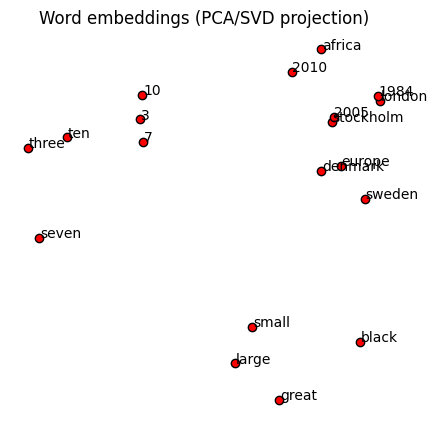

In [30]:
# Task 5.3 (optional) - 2D visualization of embeddings via PCA/SVD

import numpy as np
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt

def plot_embeddings_pca(emb, voc, words):
    vectors = np.vstack([emb.weight[voc[w]].detach().cpu().numpy() for w in words])
    vectors = vectors - vectors.mean(axis=0)
    twodim = TruncatedSVD(n_components=2).fit_transform(vectors)

    plt.figure(figsize=(5, 5))
    plt.scatter(twodim[:, 0], twodim[:, 1], edgecolors='k', c='r')
    for word, (x, y) in zip(words, twodim):
        plt.text(x + 0.02, y, word)
    plt.axis('off')
    plt.title('Word embeddings (PCA/SVD projection)')
    plt.show()


plot_words = ['sweden', 'denmark', 'europe', 'africa', 'london', 'stockholm', 'large', 'small', 'great', 'black', '3', '7', '10', 'seven', 'three', 'ten', '1984', '2005', '2010']
# Only keep words that are actually in our vocabulary.
plot_words = [w for w in plot_words if w in tokenizer.stoi]


plot_embeddings_pca(model.embedding, tokenizer.stoi, plot_words)